In [1]:
# for package auto reload
%load_ext autoreload
%autoreload 2

%matplotlib inline

## Load and Explore Data

In [11]:
import pandas as pd

dataset_path = "hotel_bookings.csv"
raw_data = pd.read_csv(dataset_path, delimiter=',', low_memory=False)

raw_data.head(7)



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03


In [ ]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## Data Preprocessing 


In [5]:
def display_all(df):
    with pd.option_context("display.max_rows", 1000, "display.max_columns", 1000): 
        display(df)
display_all(raw_data.isnull().sum().sort_values(ascending=False))

company                           112593
agent                              16340
country                              488
children                               4
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
hotel                                  0
previous_cancellations                 0
days_in_waiting_list                   0
customer_type                          0
adr                                    0
required_car_parking_spaces            0
total_of_special_requests              0
reservation_status                     0
previous_bookings_not_canceled         0
is_repeated_guest                      0
is_canceled                            0
distribution_channel                   0
market_segment                         0
meal                                   0
babies                                 0
adults                                 0
stays_in_week_ni

In [4]:
# For predicting booking cancellation 
# Not cancelled = 0 , cancelled = 1

numerical_columns = raw_data.select_dtypes(include='number')
categorical_columns = raw_data.select_dtypes(include='category')



In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

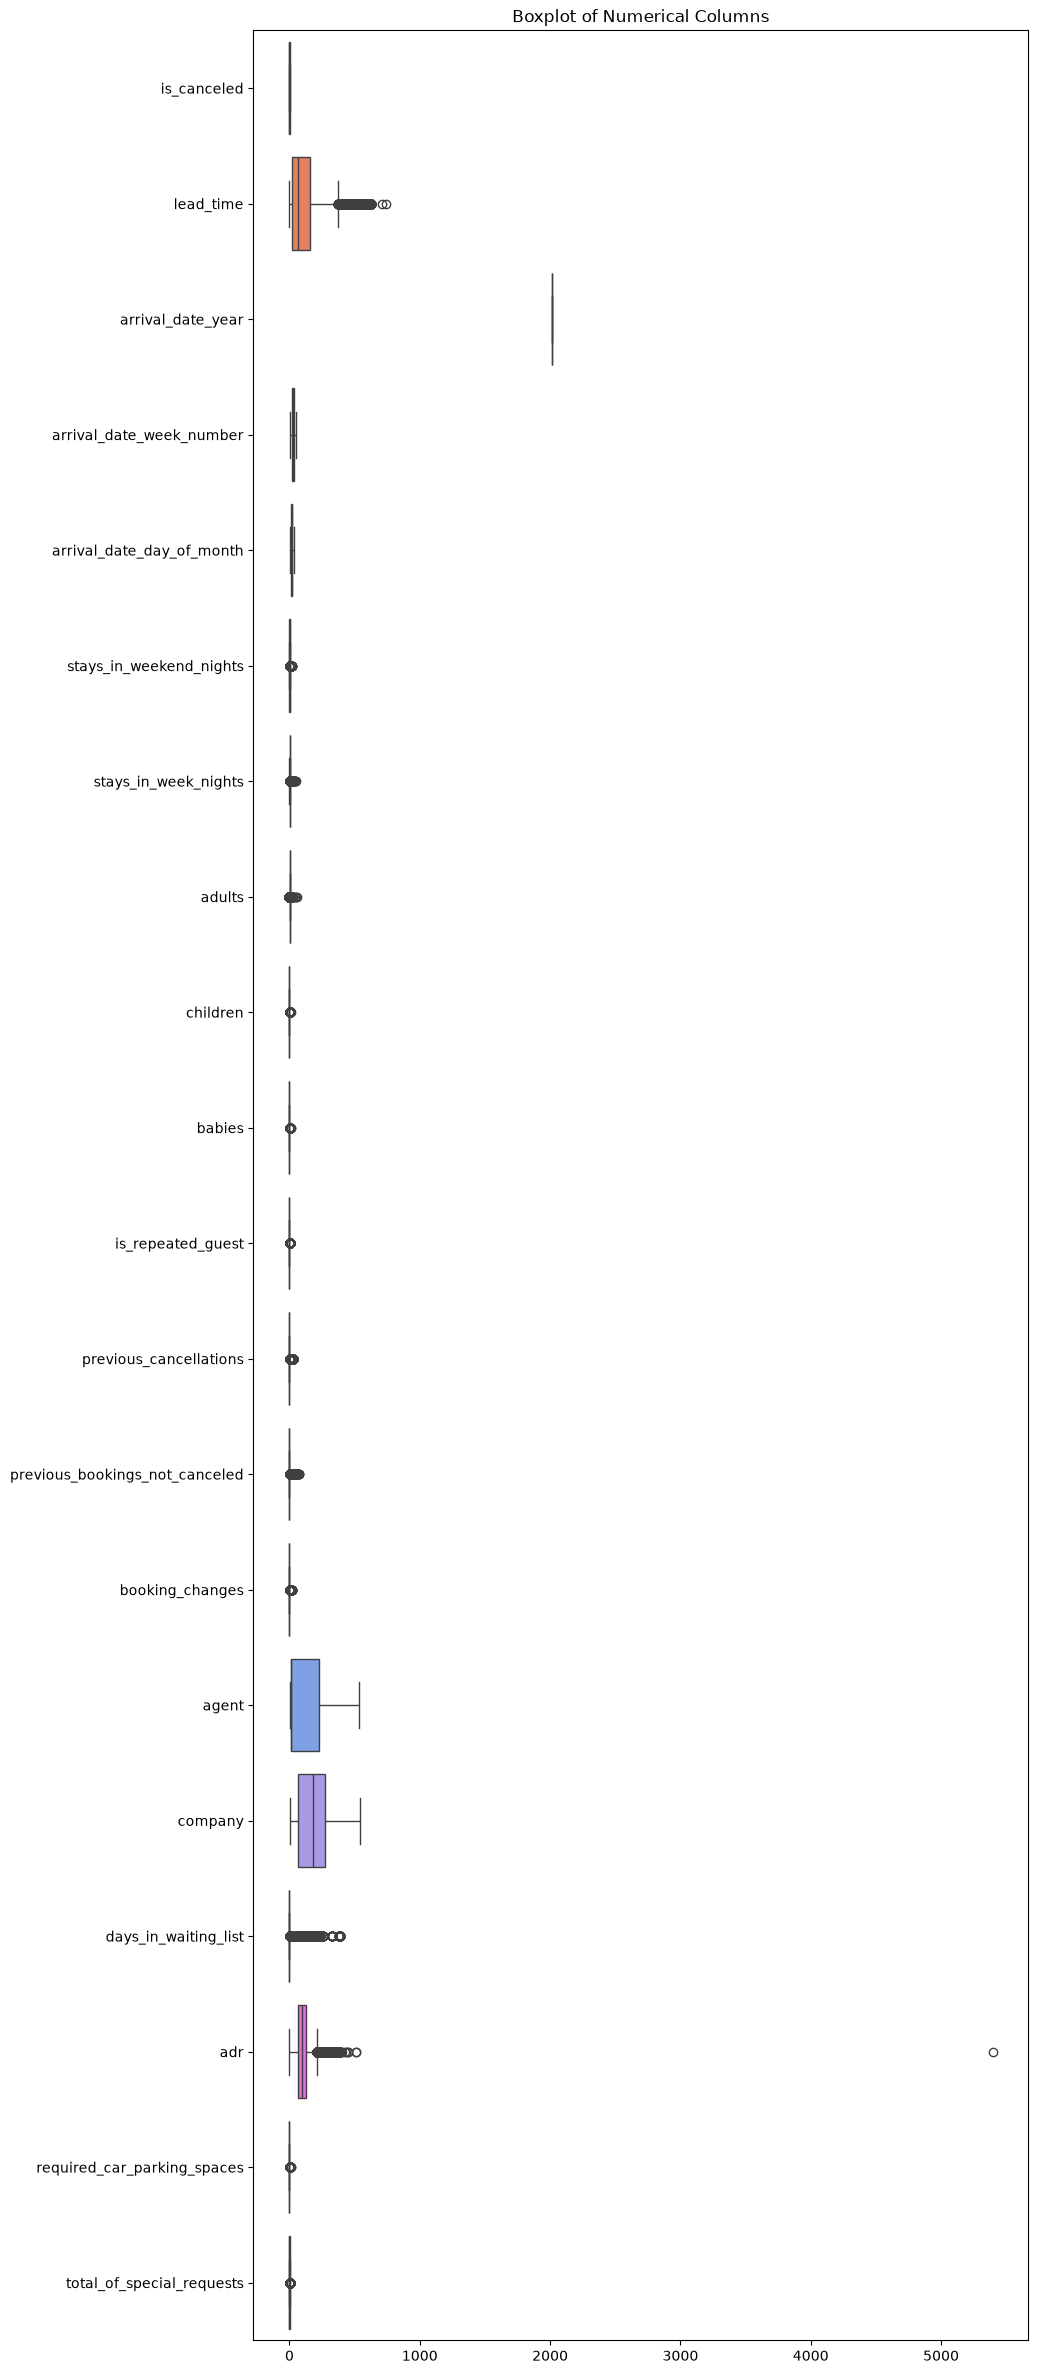

In [10]:
# Boxplot
plt.figure(figsize=(10, 30))
sns.boxplot(data=numerical_columns, orient='h')
plt.title('Boxplot of Numerical Columns')
plt.show()

In [ ]:
#Corelation


## First attempt of Modeling 
#### A classification model to predict which bookings are likely to be canceled

In [13]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification


In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    min_impurity_decrease=0.001,
    random_state=42
)
tree.fit(X_train, y_train)

# probabilities
proba = tree.predict_proba(X_test)[:, 1]

# apply your own threshold
threshold = 0.4
y_pred = (proba >= threshold).astype(int)

print(classification_report(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, proba))

NameError: name 'X' is not defined

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X,Y)
model.fit(raw_data.drop('is_canceled','categorical_columns', axis=1), raw_data['is_canceled'])


TypeError: DataFrame.drop() takes from 1 to 2 positional arguments but 3 positional arguments (and 1 keyword-only argument) were given